# Task 11 — Delivery promise: a shorter promise without more late orders

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (nine relational tables: orders, items, payments, reviews, customers, sellers, products, geolocation, category translation)
**Task family:** checkout-time delivery-time regression, a promise/late-rate frontier, censored labels, drift · **Companion task:** `02_card_fraud_tabular.ipynb` (forward evaluation, operating point from business constants, label delay)

---

## The task card

> **Board question.** *Customers are promised 25 days on average for a parcel that usually arrives in 11, and 8.8 % of orders still miss the date or never arrive. Can a model at checkout shorten the promise, and by how many days, without more late orders and without more 1-star reviews?*

**Business context.** Olist is a marketplace: small sellers ship through logistics partners, and the customer sees one estimated delivery date at checkout. That date sells (a shorter one is assumed to convert better, an assumption we price) and binds (a broken one costs stars). The service is Session 01's *online prediction* pattern: `POST /promise` answers while the customer waits, inside a legacy estate of storefront, order management, seller portal, carriers, customer service and review survey. Its label arrives weeks later, with the parcel.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given checkout-time **delivery-time model**, packaged and reproducible, evaluated forward with labels as known on the training day;
2. an **operating point** on the promise/late-rate frontier, priced with stated assumptions (an ADR);
3. the **operational wrapper**: package, CI gate, registry, model card, monitoring;
4. a small **knowledge base** with SHACL and an ablation, and grounded context for an assistant.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | A promise service in checkout; OMS, carriers, customer service and reviews as the legacy estate |
| 2 · MLOps | Censored labels, forward validation, a frontier instead of a threshold, drift |
| 3 · Semantic layer | Place, seller and category ontology on schema.org; SHACL; ablation |
| 4 · LLM/RAG | A "where is my order?" assistant grounded in order facts and a synthetic handbook |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real**: Olist's orders from 2016–2018, anonymised by Olist. Reviews are free text by real people: we keep scores, dates and aggregate phrase counts, never the text. And the dataset is famous: Kaggle lists 905 public notebooks on it (October 2026), and the unit's lecture used it. Copying is easy and earns nothing; marks go to the censored label, the frontier, the buffer and the drift.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look at lateness and slack | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–5 | Checkout-time features, the censored median model, the promise/late-rate frontier and buffer, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 6–10 | The network's drift after the cut, the place knowledge base, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 6 shows the drift your monitoring must catch; Section 7's knowledge base serves the model's place features. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `pseudonym`, `haversine_km` and `load_olist` (Section 1); `window_count` (Section 2); `asof_mean`, `days_asof`, `train_target`, `fit`, `mae`, `frontier`, `buffer_for` and `promise_at` (Section 3); `one_star`, `policy` and `saved` (Section 4); `psi` and `psi_cat` for monitoring (Section 6); `ablation_row` and `wismo_context` (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 31 features; 38,757 training orders (859 censored at the cut), 5,620 validation and 33,687 test (Feb–Jun 2018); validation MAE 5.08 days, test MAE 5.62; a +14.5-day buffer chosen on December 2017, giving 5.6 % late at a mean promise of 28.8 days on test; 2.39 days saved at the legacy's late rate of 10.6 % (bootstrap 95 % interval 2.33–2.91).
- **Runtime:** about 1 minute on a laptop (51 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, time, hmac, hashlib, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import rdflib
import pyshacl
from rdflib import Graph, Literal, Namespace, URIRef
from rdflib.namespace import RDF, RDFS, SKOS, XSD
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                                # one thread: faster on a shared laptop, and deterministic
KAGGLE_HANDLE = "olistbr/brazilian-ecommerce"
WINDOW_START, WINDOW_END = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-07-01")   # purchases; later ones are truncated (Trap 1)
TRAIN_END = pd.Timestamp("2017-12-01")    # train: orders bought Jan – Nov 2017
VALID_END = pd.Timestamp("2018-01-01")    # validation (choose the buffer): Dec 2017
CUT = pd.Timestamp("2018-02-01")          # the day the model is trained and frozen: labels only as known that day
#                                           Jan 2018 is the maturity gap; test = Feb – Jun 2018, outcomes final in the extract
ETA_QUANTILE = 0.5                        # the model predicts the median delivery day; a buffer turns it into a promise
MAX_LATE_RATE = 0.08                      # the board's tolerance for orders not delivered by the promised date (assumption — task C3)
COST_LATE_BRL = 30.0                      # contact centre, voucher and lost repeat purchase per late order (assumption — task C3)
VALUE_PER_DAY_BRL = 0.50                  # conversion value of a promise one day shorter, per order (assumption — task C3)
GATE_MIN_DAYS_SAVED = 1.0                 # CI gate: days shorter than the legacy promise at its own late rate (placeholder — task C4)
PSI_ALERT = 0.25

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "olist", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · numpy {np.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · numpy 2.5.4 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `pseudonym`, `haversine_km` and `load_olist`.*

| Field | Value |
|---|---|
| **Source** | Kaggle `olistbr/brazilian-ecommerce`, published by Olist |
| **Licence** | CC BY-NC-SA 4.0 (non-commercial, share-alike): a university course is non-commercial use; a paid product is not |
| **Provenance** | Real orders, anonymised by Olist (opaque IDs; partner names in review text replaced by Game of Thrones houses, counted below) |
| **Size** | 99,441 orders (4 Sep 2016 – 17 Oct 2018), 112,650 items, 103,886 payments, 99,224 reviews, 96,096 customers, 3,095 sellers, 32,951 products, 73 categories, 1,000,163 geolocation rows; 126 MB |
| **Files** | Nine CSVs (sizes below); geolocation (61 MB) only supplies centroids |
| **Schema (orders)** | status; purchase, approval, carrier hand-off and delivery timestamps; the **estimated delivery date** shown at checkout |
| **Label** | calendar days from purchase to delivery; *late* = delivered after the estimated date, or never delivered |
| **Window used here** | purchases Jan 2017 – Jun 2018, 85,251 orders without cancellations. Train Jan–Nov 2017, buffer on Dec 2017, both with labels as known on 1 Feb 2018; test Feb–Jun 2018 |
| **PII** | customer IDs keyed-hashed; city and zip prefix dropped after the centroid lookup (kept: state, centroid rounded to 0.1°); review text reduced on load to flags and counts. State, timestamps and basket still allow re-identification |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **The label is right-censored and the extract right-truncated.** At any snapshot the newest weeks hold only fast deliveries; and the extract seems to keep a July–August 2018 order only if its review existed by 31 August, so slow ones are missing (Trap 1). We stop at June 2018.
2. ⚠ **Columns written after checkout:** approval, hand-off, delivery and every review field. The survey goes out "once the customer receives the product, or the estimated delivery date is due" (dataset description) (Trap 2).
3. ⚠ **The estimated date is the legacy system's output**: benchmark and tempting feature (Trap 4).
4. **"Late" needs a definition:** timestamp against midnight of the estimated date gives 8.23 % of delivered orders in the window; calendar days give 7.09 %. A promise is a date, so we compare days and count never-delivered orders as late.
5. **Status is a snapshot.** 1,107 orders are stuck at *shipped*, 314 at *invoiced*, 301 at *processing*; in the window they count as never delivered. A few are *delivered* without a date (removed).
6. **Edges:** 329 orders before 2017 and 12,824 after June 2018 (truncated) fall outside the window. 1,278 orders have several sellers; an order takes its most expensive item's seller and category.
7. **Imperfect reference data:** 2 untranslated categories, 610 products without a category, 42 geolocation points outside Brazil, 84 hand-offs dated before the purchase, sellers whose state disagrees with their postcode (Section 7).

In [2]:
F = {"orders": "olist_orders_dataset.csv", "items": "olist_order_items_dataset.csv",
     "payments": "olist_order_payments_dataset.csv", "reviews": "olist_order_reviews_dataset.csv",
     "customers": "olist_customers_dataset.csv", "sellers": "olist_sellers_dataset.csv",
     "products": "olist_products_dataset.csv", "categories": "product_category_name_translation.csv",
     "geo": "olist_geolocation_dataset.csv"}
WISMO = r"n[aã]o recebi|ainda n[aã]o|n[aã]o chegou|n[aã]o foi entregue|nao entregue"   # "not received", "not yet", ...
GOT_HOUSES = ["stark", "lannister", "targaryen", "baratheon"]
CACHE = {k: PROCESSED / f"11_{k}.parquet" for k in ["orders", "sellers", "categories", "phrases", "meta"]}

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def pseudonym(x: str) -> str:
    """Keyed hash: joins still work, Olist's customer ID does not leave this frame."""
    key = os.environ.get("OLIST_PSEUDONYM_KEY", "teaching-only-key").encode()      # production: a secret store
    return hmac.new(key, x.encode(), hashlib.sha256).hexdigest()[:12]

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def load_olist() -> dict:
    if all(p.exists() for p in CACHE.values()):
        return {k: pd.read_parquet(p) for k, p in CACHE.items()}
    t = time.time()
    dates = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
    o = pd.read_csv(get_raw(F["orders"]), parse_dates=dates)
    o.columns = ["order_id", "customer_id", "status", "purchased", "approved", "carrier", "delivered", "estimated"]
    # ---- places: one centroid per 5-digit zip prefix (the 1 M-row geolocation file is read once, 4 columns) ----
    geo = pd.read_csv(get_raw(F["geo"]), usecols=[0, 1, 2, 4], dtype={"geolocation_lat": "float32", "geolocation_lng": "float32"})
    geo.columns = ["zip", "lat", "lng", "state"]
    geo_rows = len(geo)
    geo = geo[geo.lat.between(-34, 5.5) & geo.lng.between(-74, -34)]          # 42 points fall outside Brazil
    places = geo.groupby("zip").agg(lat=("lat", "median"), lng=("lng", "median"), zip_state=("state", lambda s: s.mode().iat[0]))
    # ---- governance: pseudonymise the customer; keep the state and a coarse centroid, drop city and zip ----
    cust = pd.read_csv(get_raw(F["customers"]))
    cust["cust_pid"] = cust.customer_unique_id.map(pseudonym)
    cust = cust.join(places[["lat", "lng"]], on="customer_zip_code_prefix")
    o = o.merge(cust[["customer_id", "cust_pid", "customer_state", "lat", "lng"]], on="customer_id", how="left")
    o = o.drop(columns="customer_id").rename(columns={"lat": "c_lat_exact", "lng": "c_lng_exact"})
    # ---- items, products, categories, sellers: one row per order, led by its most expensive item ----
    it = pd.read_csv(get_raw(F["items"]))
    prod = pd.read_csv(get_raw(F["products"]))
    cats = pd.read_csv(get_raw(F["categories"]))
    sel = pd.read_csv(get_raw(F["sellers"])).rename(columns={"seller_zip_code_prefix": "zip"}).join(places, on="zip")
    it = it.merge(prod, on="product_id", how="left").merge(cats, on="product_category_name", how="left")
    it["category"] = it.product_category_name_english.fillna(it.product_category_name).fillna("unknown")
    it["volume_l"] = it.product_length_cm * it.product_height_cm * it.product_width_cm / 1000
    it = it.sort_values(["order_id", "price"], ascending=[True, False])
    agg = it.groupby("order_id").agg(
        n_items=("order_item_id", "size"), n_sellers=("seller_id", "nunique"), price=("price", "sum"),
        freight=("freight_value", "sum"), weight_kg=("product_weight_g", "sum"), volume_l=("volume_l", "sum"),
        photos=("product_photos_qty", "mean"), category=("category", "first"), seller_id=("seller_id", "first"))
    agg["weight_kg"] /= 1000
    o = o.merge(agg, left_on="order_id", right_index=True, how="left")
    o = o.merge(sel[["seller_id", "seller_state", "lat", "lng"]].rename(columns={"lat": "s_lat", "lng": "s_lng"}),
                on="seller_id", how="left")
    o["dist_km"] = haversine_km(o.c_lat_exact, o.c_lng_exact, o.s_lat, o.s_lng)
    o["c_lat"], o["c_lng"] = o.c_lat_exact.round(1), o.c_lng_exact.round(1)       # ≈ 11 km: enough for routing
    o = o.drop(columns=["c_lat_exact", "c_lng_exact"])
    pay = pd.read_csv(get_raw(F["payments"])).sort_values("payment_value", ascending=False)
    pay = pay.groupby("order_id").agg(pay_type=("payment_type", "first"), installments=("payment_installments", "max"),
                                      n_pay=("payment_sequential", "size"))
    o = o.merge(pay, left_on="order_id", right_index=True, how="left")
    # ---- reviews: keep score and dates; reduce the free text to two flags and aggregate counts, then drop it ----
    rv = pd.read_csv(get_raw(F["reviews"]), parse_dates=["review_creation_date", "review_answer_timestamp"])
    text = (rv.review_comment_title.fillna("") + " " + rv.review_comment_message.fillna("")).str.lower()
    meta = {f"got_{h}": int(text.str.contains(h).sum()) for h in GOT_HOUSES}
    meta.update(reviews=len(rv), review_orders=rv.order_id.nunique(), comments=int(rv.review_comment_message.notna().sum()))
    rv["has_comment"] = rv.review_comment_message.notna()
    rv["wismo_phrase"] = text.str.contains(WISMO)
    rv["msg"] = rv.review_comment_message.str.lower().str.replace(r"[^\w\s]", " ", regex=True)
    rv = rv.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")   # latest review per order
    o = o.merge(rv[["order_id", "review_score", "review_creation_date", "has_comment", "wismo_phrase", "msg"]]
                .rename(columns={"review_creation_date": "review_created"}), on="order_id", how="left")
    late = (o.delivered.isna() | (o.delivered.dt.normalize() > o.estimated)) & ~o.status.isin(["canceled", "unavailable"])
    tri = Counter()
    for m in o.loc[late & o.msg.notna(), "msg"]:
        w = m.split(); tri.update(" ".join(w[i:i + 3]) for i in range(len(w) - 2))
    phrases = pd.DataFrame(tri.most_common(8), columns=["trigram in late orders' comments", "count"])
    o = o.drop(columns="msg"); del rv, text, tri                              # no free text is kept beyond this point
    o["has_comment"] = o.has_comment.astype("boolean"); o["wismo_phrase"] = o.wismo_phrase.astype("boolean")
    sellers = sel[["seller_id", "zip", "seller_state", "lat", "lng", "zip_state"]]
    cat_tbl = pd.DataFrame({"category_pt": sorted(prod.product_category_name.dropna().unique())}).merge(
        cats.rename(columns={"product_category_name": "category_pt", "product_category_name_english": "category_en"}), how="left")
    meta.update(products=len(prod), products_no_category=int(prod.product_category_name.isna().sum()), items=len(it),
                payments=int(pay.n_pay.sum()), geo_rows=geo_rows, geo_outside=geo_rows - len(geo), zip_prefixes=len(places))
    out = {"orders": o, "sellers": sellers, "categories": cat_tbl, "phrases": phrases, "meta": pd.DataFrame([meta])}
    for k, df in out.items():
        df.to_parquet(CACHE[k])
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return out

D = load_olist()
orders_all, sellers, categories, phrases = D["orders"], D["sellers"], D["categories"], D["phrases"]
meta = D["meta"].iloc[0]
print(f"{len(orders_all):,} orders bought {orders_all.purchased.min():%d %b %Y} – {orders_all.purchased.max():%d %b %Y} · "
      f"{orders_all.cust_pid.nunique():,} customers (pseudonymised) · {len(sellers):,} sellers · {meta.products:,} products "
      f"({meta.products_no_category} without category) · {len(categories)} categories ({categories.category_en.isna().sum()} without "
      f"an English name) · {orders_all.memory_usage(deep=True).sum()/1e6:.0f} MB")
print(f"{meta['items']:,} items · {meta.payments:,} payments · {meta.geo_rows:,} geolocation rows ({meta.geo_outside} outside Brazil) "
      f"→ {meta.zip_prefixes:,} zip-prefix centroids · orders with 2+ sellers: {int((orders_all.n_sellers > 1).sum()):,}")
print(f"reviews: {meta.reviews:,} for {meta.review_orders:,} orders, {meta.comments:,} with a comment (text dropped on load) · "
      "Game of Thrones house names in the text: " + ", ".join(f"{h} {meta['got_' + h]:,}" for h in GOT_HOUSES))
print("status: " + " · ".join(f"{k} {v:,}" for k, v in orders_all.status.value_counts().items()))
print("files: " + " · ".join(f"{f.replace('olist_', '').replace('_dataset', '')} {get_raw(f).stat().st_size / 1e6:.1f} MB"
                             for f in F.values()))

99,441 orders bought 04 Sep 2016 – 17 Oct 2018 · 96,096 customers (pseudonymised) · 3,095 sellers · 32,951 products (610 without category) · 73 categories (2 without an English name) · 33 MB


112,650 items · 103,886 payments · 1,000,163 geolocation rows (42 outside Brazil) → 19,010 zip-prefix centroids · orders with 2+ sellers: 1,278
reviews: 99,224 for 98,673 orders, 40,977 with a comment (text dropped on load) · Game of Thrones house names in the text: stark 305, lannister 1,224, targaryen 281, baratheon 277
status: delivered 96,478 · shipped 1,107 · canceled 625 · unavailable 609 · invoiced 314 · processing 301 · created 5 · approved 2
files: orders.csv 17.7 MB · order_items.csv 15.4 MB · order_payments.csv 5.8 MB · order_reviews.csv 14.5 MB · customers.csv 9.0 MB · sellers.csv 0.2 MB · products.csv 2.4 MB · product_category_name_translation.csv 0.0 MB · geolocation.csv 61.3 MB


## 2 · First look: lateness is what customers punish

*Part A · Explore · read; the 1-star cost of lateness and the 11-day median frame the operating point.*

First: does lateness cost anything, and how much slack is in today's promise?

In [3]:
REGIONS = {"North": "AC AP AM PA RO RR TO", "Northeast": "AL BA CE MA PB PE PI RN SE",      # IBGE macro-regions
           "Center-West": "DF GO MT MS", "Southeast": "ES MG RJ SP", "South": "PR RS SC"}
STATE_REGION = {s: r for r, ss in REGIONS.items() for s in ss.split()}
EXTRACT_END = orders_all.review_created.max().normalize() + pd.Timedelta(days=1)   # the last review: when the extract was cut

o = orders_all.copy()
o["seller_id"] = o.seller_id.fillna("none"); o["seller_state"] = o.seller_state.fillna("??")

def window_count(df: pd.DataFrame, key: str, days: int) -> pd.Series:
    """Orders with the same key bought in the `days` before each order (the OMS knows these at checkout)."""
    d = df[[key, "purchased"]].sort_values([key, "purchased"])
    secs = d.purchased.values.astype("datetime64[s]").astype(np.int64); k = d[key].values
    out = np.zeros(len(d))
    starts = np.r_[0, np.flatnonzero(k[1:] != k[:-1]) + 1, len(d)]
    for s, e in zip(starts[:-1], starts[1:]):
        ts = secs[s:e]; out[s:e] = np.arange(e - s) - np.searchsorted(ts, ts - days * 86400, side="left")
    return pd.Series(out, index=d.index).reindex(df.index)

o["platform_orders_7d"] = window_count(o.assign(all_orders="x"), "all_orders", 7)
o["seller_orders_7d"] = window_count(o, "seller_id", 7)
in_window = (o.purchased >= WINDOW_START) & (o.purchased < WINDOW_END)
cancelled = in_window & o.status.isin(["canceled", "unavailable"])
no_date = in_window & (o.status == "delivered") & o.delivered.isna()
o = o[in_window & ~cancelled & ~no_date].sort_values("purchased").reset_index(drop=True)
o["pday"] = o.purchased.dt.normalize()
o["y_days"] = (o.delivered.dt.normalize() - o.pday).dt.days              # calendar days to delivery; NaN = never delivered
o["legacy_promise"] = (o.estimated - o.pday).dt.days                       # the date shown to the customer at purchase
y_final = o.y_days.fillna(np.inf).values
o["outcome"] = np.select([o.y_days.isna(), y_final > o.legacy_promise], ["never delivered", "late"], "on time")
print(f"population: {len(o):,} orders bought {WINDOW_START:%b %Y} – {WINDOW_END - pd.Timedelta(days=1):%b %Y} · excluded "
      f"{int(cancelled.sum()):,} cancelled or unavailable and {int(no_date.sum())} 'delivered' without a date · outside the window: "
      f"{int((orders_all.purchased < WINDOW_START).sum())} before, {int((orders_all.purchased >= WINDOW_END).sum()):,} after · "
      f"extract effectively ends {EXTRACT_END - pd.Timedelta(days=1):%d %b %Y} (last review)")

link = o.groupby("outcome").agg(orders=("order_id", "size"), mean_stars=("review_score", "mean"),
                                one_star=("review_score", lambda s: (s == 1).mean()),
                                not_received_phrase=("wismo_phrase", lambda s: s.fillna(False).mean()))
link.insert(1, "share", link.orders / link.orders.sum())
display(link.style.format({"orders": "{:,}", "share": "{:.1%}", "mean_stars": "{:.2f}", "one_star": "{:.1%}",
                           "not_received_phrase": "{:.1%}"}))
deliv = o.y_days.notna()
print(f"promises broken (late or never delivered): {(o.outcome != 'on time').mean():.1%} · "
      f"late among delivered orders: {(o.loc[deliv, 'outcome'] == 'late').mean():.2%} by calendar day "
      f"({(o.delivered > o.estimated)[deliv].mean():.2%} if the timestamp is compared with the date at midnight) · "
      f"promise: mean {o.legacy_promise.mean():.1f}, median {o.legacy_promise.median():.0f} days · "
      f"delivery: median {o.y_days.median():.0f}, 90th percentile {o.y_days.quantile(0.9):.0f} days")
display(phrases.set_index(phrases.columns[0]).T)

population: 85,251 orders bought Jan 2017 – Jun 2018 · excluded 1,032 cancelled or unavailable and 5 'delivered' without a date · outside the window: 329 before, 12,824 after · extract effectively ends 31 Aug 2018 (last review)


,orders,share,mean_stars,one_star,not_received_phrase
outcome,,,,,
late,"5,930",7.0%,2.21,54.2%,25.0%
never delivered,"1,555",1.8%,1.79,65.6%,26.1%
on time,"77,766",91.2%,4.28,6.7%,1.7%


promises broken (late or never delivered): 8.8% · late among delivered orders: 7.09% by calendar day (8.23% if the timestamp is compared with the date at midnight) · promise: mean 25.3, median 24 days · delivery: median 11, 90th percentile 24 days


trigram in late orders' comments,recebi o produto,não recebi o,ainda não recebi,não foi entregue,o produto não,prazo de entrega,o produto e,até o momento
count,597,540,302,278,193,153,147,143


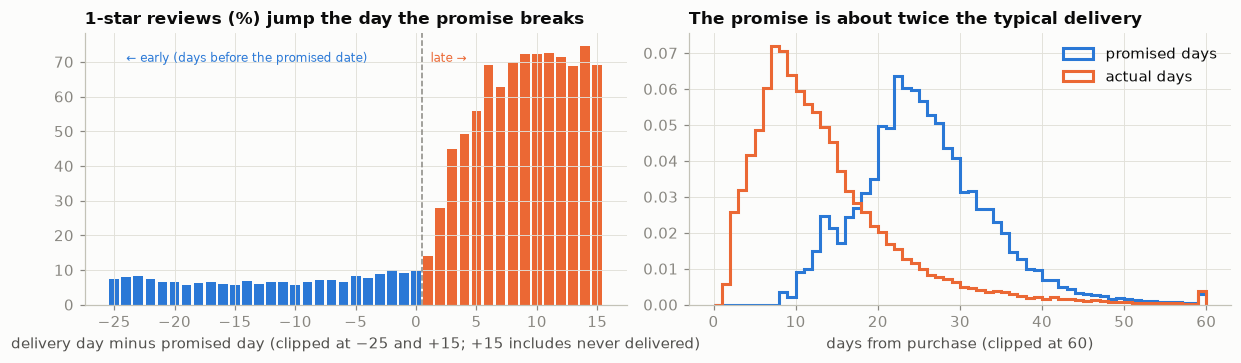

In [4]:
rel = pd.Series(np.clip(y_final - o.legacy_promise.values, -25, 15), index=o.index)
has_rev = o.review_score.notna()
by_rel = (o.review_score[has_rev] == 1).groupby(rel[has_rev]).agg(["mean", "size"])
by_rel = by_rel[by_rel["size"] >= 100]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.bar(by_rel.index, by_rel["mean"] * 100, width=0.8, color=[SERIES[1] if d > 0 else SERIES[0] for d in by_rel.index])
ax.axvline(0.5, color=MUTED, ls="--", lw=1); ax.text(1.2, 70, "late →", color=SERIES[1], fontsize=8)
ax.text(-24, 70, "← early (days before the promised date)", color=SERIES[0], fontsize=8)
ax.set_xlabel("delivery day minus promised day (clipped at −25 and +15; +15 includes never delivered)")
ax.set_title("1-star reviews (%) jump the day the promise breaks")
ax = axes[1]
bins = np.arange(0, 61, 1)
ax.hist(o.legacy_promise.clip(upper=60), bins=bins, density=True, histtype="step", lw=2, color=SERIES[0], label="promised days")
ax.hist(o.y_days.dropna().clip(upper=60), bins=bins, density=True, histtype="step", lw=2, color=SERIES[1], label="actual days")
ax.set_xlabel("days from purchase (clipped at 60)"); ax.legend()
ax.set_title("The promise is about twice the typical delivery")
plt.tight_layout()

A late parcel averages 2.21 stars and draws a 1-star review 54.2 % of the time; one that never arrives, 1.79 stars and 65.6 %; an on-time one, 4.28 and 6.7 %. The damage begins on the promised day and saturates within about a week; arriving early earns little (Section 4 prints the steps). And there is plenty of slack: the promise averages 25.3 days against a median delivery of 11 and a 90th percentile of 24. One late customer in four writes some version of *I have not received it* (25.0 % against 1.7 % on time), the Stretch assistant's questions. So: how much of the gap between 11 and 25 days can go without pushing more parcels past the date?

# Part B — The given model

*Sections 3–5: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · A promise model at checkout

*Part B · Given model · package `asof_mean`, `train_target`, `fit` and `promise_at` unchanged and reproduce the numbers (C2); C1 tests the censoring rule.*

At checkout the model answers one question: *on which day will this parcel most likely arrive?* The promise is that prediction plus a **buffer**, a business decision (Section 4). Every feature must be known when the customer presses *Buy*:

- **Order**: items, price, freight, weight, volume, category, payment, hour, weekday, platform and seller orders in the previous seven days, customer state and coarse location.
- **Seller history, as of the purchase**: mean handling and delivery times over the seller's earlier orders already handed off or delivered, checked against brute force (the seed of C1's test).
- **Place context** (served by the knowledge base, Section 7): seller state and region, customer region, route class, distance, the route's as-of transit time.

In [5]:
def asof_mean(df: pd.DataFrame, key: str, event: str, value: str, name: str) -> None:
    """Mean of `value` over the same key's earlier orders whose `event` happened BEFORE this order was bought."""
    E = df[[key, event, value]].dropna().sort_values(event)
    E["cs"] = E.groupby(key)[value].cumsum(); E["cn"] = E.groupby(key).cumcount() + 1
    Q = df[["purchased", key]].reset_index().sort_values("purchased")
    m = pd.merge_asof(Q, E[[key, event, "cs", "cn"]].rename(columns={event: "t"}), left_on="purchased", right_on="t",
                      by=key, allow_exact_matches=False).set_index("index").sort_index()
    df[name] = m.cs / m.cn
    df[name.replace("_days", "_n")] = m.cn.fillna(0)

o["handling"] = ((o.carrier - o.purchased).dt.total_seconds() / 86400).where(lambda s: s >= 0)   # negative = data error
o["transit"] = ((o.delivered - o.carrier).dt.total_seconds() / 86400).where(lambda s: s >= 0)
o["total"] = (o.delivered - o.purchased).dt.total_seconds() / 86400
o["route"] = o.seller_state + ">" + o.customer_state
asof_mean(o, "seller_id", "carrier", "handling", "seller_hist_handling_days")
asof_mean(o, "seller_id", "delivered", "total", "seller_hist_total_days")
asof_mean(o, "route", "delivered", "transit", "route_hist_transit_days")
o["hour"], o["dow"] = o.purchased.dt.hour, o.purchased.dt.day_of_week
o["freight_ratio"] = o.freight / o.price
o["customer_region"] = o.customer_state.map(STATE_REGION)
o["seller_region"] = o.seller_state.map(STATE_REGION).fillna("unknown")
o["route_class"] = np.select([o.seller_state == o.customer_state, o.seller_region == o.customer_region],
                             ["same state", "same region"], "inter-region")
for c in ["category", "pay_type", "customer_state", "seller_state", "customer_region", "seller_region", "route_class"]:
    o[c] = o[c].astype("category")

ORDER = ["n_items", "n_sellers", "price", "freight", "freight_ratio", "weight_kg", "volume_l", "photos", "category",
         "pay_type", "installments", "n_pay", "hour", "dow", "platform_orders_7d", "seller_orders_7d",
         "customer_state", "c_lat", "c_lng", "seller_hist_handling_days", "seller_hist_handling_n", "seller_hist_total_days"]
PLACE = ["seller_state", "seller_region", "customer_region", "route_class", "dist_km", "s_lat", "s_lng",
         "route_hist_transit_days", "route_hist_transit_n"]                # the seller-region context (Section 7)
FEATURES = ORDER + PLACE

# as-of check (the test task C1 asks for): recompute a seller-history feature by brute force on a sample
rng = np.random.default_rng(SEED)
chk = []
for i in rng.choice(np.flatnonzero(o.seller_hist_total_days.notna()), 200, replace=False):
    r = o.iloc[i]
    past = o[(o.seller_id == r.seller_id) & (o.delivered < r.purchased)]
    chk.append(abs(past.total.mean() - r.seller_hist_total_days))
print(f"{len(FEATURES)} features ({len(ORDER)} order, {len(PLACE)} place) · as-of check on 200 orders: "
      f"max |brute force − feature| = {max(chk):.1e} days · hand-off before purchase (set to missing): "
      f"{int(((o.carrier - o.purchased).dt.total_seconds() < 0).sum())} orders")

31 features (22 order, 9 place) · as-of check on 200 orders: max |brute force − feature| = 3.6e-15 days · hand-off before purchase (set to missing): 84 orders


Labels follow a **censoring rule**: trained on 1 Feb 2018 (`CUT`), the model sees only deliveries made by then, and an order still in transit keeps its age as a lower bound, the right direction for a median. January 2018 is left out: on the cut, only 58 % of its orders had arrived (Trap 1). The learner is LightGBM with a quantile loss at α = 0.5. The test window, Feb–Jun 2018, is scored with final outcomes.

In [6]:
def days_asof(d: pd.DataFrame, asof: pd.Timestamp) -> np.ndarray:
    """Days to delivery as known on `asof`; inf = not delivered by then (late under any promise shorter than its age)."""
    return np.where(d.delivered < asof, d.y_days, np.inf)

def train_target(d: pd.DataFrame, asof: pd.Timestamp) -> np.ndarray:
    """The censoring rule: an order still undelivered on `asof` keeps its age as a lower bound."""
    y = days_asof(d, asof)
    return np.where(np.isfinite(y), y, (asof.normalize() - d.pday).dt.days.values)

tr = o[o.purchased < TRAIN_END]
va = o[(o.purchased >= TRAIN_END) & (o.purchased < VALID_END)]
gap = o[(o.purchased >= VALID_END) & (o.purchased < CUT)]
te = o[o.purchased >= CUT]
y_tr, y_va, y_te = train_target(tr, CUT), days_asof(va, CUT), days_asof(te, EXTRACT_END)
print(f"train {len(tr):,} orders (Jan–Nov 2017; {int((tr.delivered >= CUT).sum() + tr.delivered.isna().sum())} still undelivered "
      f"at the cut, kept as censored) · validation {len(va):,} (Dec 2017; {np.isinf(y_va).mean():.1%} undelivered at the cut) · "
      f"maturity gap {len(gap):,} (Jan 2018) · test {len(te):,} (Feb–Jun 2018; {np.isinf(y_te).mean():.1%} never delivered)")

LGB_PARAMS = dict(objective="quantile", n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, n_jobs=N_JOBS, verbose=-1)

def fit(cols, X, y, alpha=ETA_QUANTILE):
    return lgb.LGBMRegressor(alpha=alpha, **LGB_PARAMS).fit(X[cols], y)

def mae(y, p):
    f = np.isfinite(y)
    return float(np.abs(y[f] - p[f]).mean())

OFFSETS = np.arange(-15, 45, 0.5)
def frontier(y, base, offsets=OFFSETS) -> pd.DataFrame:
    """Late rate and mean promise for promise = ceil(base + offset), over a grid of offsets."""
    P = np.ceil(base[None, :] + offsets[:, None])
    return pd.DataFrame({"offset": offsets, "late": (y[None, :] > P).mean(1), "promise": P.mean(1)})

def buffer_for(y, base, max_late):
    f = frontier(y, base)
    return float(f[f.late <= max_late].offset.iloc[0])

def promise_at(y, base, late):
    f = frontier(y, base)
    return float(f[f.late <= late].promise.iloc[0])

t1 = time.time()
model = fit(FEATURES, tr, y_tr)
p_va, p_te = model.predict(va[FEATURES]), model.predict(te[FEATURES])
fit_s = time.time() - t1
route_median = pd.Series(y_tr, index=tr.index).groupby(tr.route.values).median()
p_route = te.route.map(route_median).astype(float).fillna(np.median(y_tr)).values
legacy_te = te.legacy_promise.values.astype(float)
legacy_late = float((y_te > legacy_te).mean())
days_saved = te.legacy_promise.mean() - promise_at(y_te, p_te, legacy_late)
m90 = fit(FEATURES, tr, y_tr, alpha=0.9)
p90_te = m90.predict(te[FEATURES])
res = pd.DataFrame({
    "MAE test (days)": [mae(y_te, np.full(len(te), np.median(y_tr))), mae(y_te, p_route), mae(y_te, p_te), np.nan],
    "mean promise at the legacy's late rate": [promise_at(y_te, np.zeros(len(te)), legacy_late), promise_at(y_te, p_route, legacy_late),
                                               promise_at(y_te, p_te, legacy_late), promise_at(y_te, p90_te, legacy_late)]},
    index=["one number (training median)", "route table (seller state → customer state median)",
           f"LightGBM median (α = {ETA_QUANTILE})", "LightGBM 90th percentile (α = 0.9)"])
print(f"legacy promise on the test window: mean {te.legacy_promise.mean():.1f} days, late {legacy_late:.1%} · "
      f"median model fitted in {fit_s:.0f}s, validation MAE {mae(y_va, p_va):.2f} days")
display(res.style.format("{:.2f}", na_rep="—"))
print(f"90th-percentile model without a buffer: {(y_te <= np.ceil(p90_te)).mean():.1%} of test orders delivered by its date "
      f"(target 90%), mean {np.ceil(p90_te).mean():.1f} days")

train 38,757 orders (Jan–Nov 2017; 859 still undelivered at the cut, kept as censored) · validation 5,620 (Dec 2017; 3.1% undelivered at the cut) · maturity gap 7,187 (Jan 2018) · test 33,687 (Feb–Jun 2018; 1.5% never delivered)


legacy promise on the test window: mean 24.7 days, late 10.6% · median model fitted in 4s, validation MAE 5.08 days


,MAE test (days),mean promise at the legacy's late rate
one number (training median),6.82,26.00
route table (seller state → customer state median),5.66,23.64
LightGBM median (α = 0.5),5.62,22.35
LightGBM 90th percentile (α = 0.9),—,24.70


90th-percentile model without a buffer: 92.8% of test orders delivered by its date (target 90%), mean 27.2 days


On **MAE** the model (5.62 days) barely beats a route lookup table (5.66), overestimating the faster spring-2018 deliveries (Section 6). On the metric that answers the board, the **mean promise needed to match the legacy's late rate** of 10.6 %, it wins clearly: 22.4 days, against 23.6 for the route table, 24.7 for the legacy estimate and 26 for one number for everyone. MAE rewards the right *level*; a promise needs the right *ranking* of which orders need slack. A 90th-percentile model, the textbook promise, needs 24.7 days (unbuffered, 92.8 % arrive on time): its tail is noisier than a median plus a buffer. The legacy beats a flat promise by 1.3 days: Olist's estimator is real, not padding.

## 4 · The operating point: promise length against late rate

*Part B · Given model · package `policy`, `saved` and `buffer_for`; C3 asks you to own the tolerance and the two constants.*

Every policy is a point on a frontier: mean promise against the share of orders late or never delivered. The board's tolerance (`MAX_LATE_RATE`, 8 %, an assumption) picks the point. The buffer is chosen on December 2017 with labels as of the cut, frozen, and applied to Feb–Jun 2018. Rows marked *test (comparison)* set their buffer on the test window: not deployable, they measure each curve's *shape*, as AUPRC does for a classifier.

**Expected 1-star** applies the training orders' 1-star share for each position against the promise, assuming reviews follow the promise kept (for the legacy it predicts 11.5 %; 12.3 % was observed, so it runs slightly low). **Value vs legacy** uses two invented constants; task C3 varies them.

In [7]:
BUFFER = buffer_for(y_va, p_va, MAX_LATE_RATE)
promise_te = np.ceil(p_te + BUFFER)
# 1-star share by days relative to the promise, learned on the training orders (reviews written before the cut)
BINS = [-np.inf, -8, -1, 0, 2, 5, 10, np.inf]
BIN_LABELS = ["8+ days early", "1–7 early", "on the day", "1–2 late", "3–5 late", "6–10 late", "11+ late or never"]
rev = (tr.review_score.notna() & (tr.review_created < CUT)).values
rel_tr = pd.cut(days_asof(tr, CUT)[rev] - tr.legacy_promise.values[rev], BINS, labels=BIN_LABELS)
ONE_STAR = pd.Series((tr.review_score.values[rev] == 1)).groupby(rel_tr.codes).mean()
ONE_STAR.index = BIN_LABELS

def one_star(y, promise):
    return float(pd.Series(pd.cut(y - promise, BINS, labels=BIN_LABELS)).map(ONE_STAR).astype(float).mean())

def policy(name, promise, note=""):
    late = float((y_te > promise).mean())
    return {"policy": name, "mean promise (days)": promise.mean(), "late rate": late, "expected 1-star": one_star(y_te, promise),
            "value vs legacy (R$ per 1,000 orders)": 1000 * (VALUE_PER_DAY_BRL * (legacy_te.mean() - promise.mean())
                                                             - COST_LATE_BRL * (late - legacy_late)), "buffer chosen on": note}

k_leg8 = buffer_for(y_te, legacy_te, MAX_LATE_RATE)
k_leg_va = buffer_for(y_va, va.legacy_promise.values.astype(float), MAX_LATE_RATE)   # the legacy's own deployable buffer
flat_n = promise_at(y_te, np.zeros(len(te)), legacy_late)
FROZEN = f"model + {BUFFER:.1f} days, frozen"
ops = pd.DataFrame([
    policy("legacy estimate (as shown at checkout)", legacy_te, "—"),
    policy(f"flat promise, {flat_n:.0f} days for everyone", np.full(len(te), flat_n), "test (comparison)"),
    policy(f"legacy + {np.ceil(k_leg8):.0f} days (meets {MAX_LATE_RATE:.0%})", np.ceil(legacy_te + k_leg8), "test (comparison)"),
    policy(f"legacy + {np.ceil(k_leg_va):.0f} days, frozen", np.ceil(legacy_te + k_leg_va), "Dec 2017 validation"),
    policy(FROZEN, promise_te, "Dec 2017 validation"),
    policy("model at the legacy's late rate", np.ceil(p_te + buffer_for(y_te, p_te, legacy_late)), "test (comparison)"),
    policy(f"model at {MAX_LATE_RATE:.0%}", np.ceil(p_te + buffer_for(y_te, p_te, MAX_LATE_RATE)), "test (comparison)"),
]).set_index("policy")
print(f"buffer chosen on validation for a late rate ≤ {MAX_LATE_RATE:.0%}: +{BUFFER:.1f} days (validation late "
      f"{(y_va > np.ceil(p_va + BUFFER)).mean():.1%}; the legacy promise ran at {(y_va > va.legacy_promise.values).mean():.1%} "
      f"with {va.legacy_promise.mean():.1f} days that month)")
print("1-star share by delivery relative to the promise (training orders): " +
      " · ".join(f"{k} {v:.1%}" for k, v in ONE_STAR.items()))
print(f"check on the test window, legacy promise: expected 1-star {one_star(y_te, legacy_te):.1%}, "
      f"observed {(te.review_score.dropna() == 1).mean():.1%}")
display(ops.style.format({"mean promise (days)": "{:.1f}", "late rate": "{:.1%}", "expected 1-star": "{:.1%}",
                          "value vs legacy (R$ per 1,000 orders)": "{:+,.0f}"}))
print(f"to match the frozen model's {ops.loc[FROZEN, 'late rate']:.1%} late, the legacy needs a mean promise of "
      f"{promise_at(y_te, legacy_te, ops.loc[FROZEN, 'late rate']):.1f} days")

# how sure is "days saved"? an order-level bootstrap and the spread by test month
def saved(y, p, leg):
    """Legacy mean promise minus the model's, with the model's buffer set to match the legacy's late rate on (y, leg)."""
    return leg.mean() - promise_at(y, p, float((y > leg).mean()))
rng_boot = np.random.default_rng(SEED + 1)        # its own generator, so later random draws do not move
boot = [saved(y_te[i], p_te[i], legacy_te[i]) for i in (rng_boot.integers(0, len(te), len(te)) for _ in range(200))]
by_month = pd.Series({m: saved(y_te[msk], p_te[msk], legacy_te[msk])
                      for m in te.purchased.dt.to_period("M").unique() for msk in [(te.purchased.dt.to_period("M") == m).values]})
print(f"days saved at the legacy's late rate: {days_saved:.2f} (bootstrap 95% interval {np.percentile(boot, 2.5):.2f}–"
      f"{np.percentile(boot, 97.5):.2f}, 200 resamples) · by test month: " + " · ".join(f"{m:%b} {v:.2f}" for m, v in by_month.items()))
gate_ok = (days_saved >= GATE_MIN_DAYS_SAVED) and (ops.loc[FROZEN, "late rate"] <= MAX_LATE_RATE)
HOLDOUT_SHA256 = hashlib.sha256(pd.DataFrame({"order_id": te.order_id.values, "days": y_te}).to_csv(index=False).encode()).hexdigest()
print(f"CI gate on the frozen holdout ({len(te):,} orders, SHA-256 {HOLDOUT_SHA256[:16]}…): {days_saved:.2f} days saved at the legacy's "
      f"late rate (≥ {GATE_MIN_DAYS_SAVED}) and frozen late rate {ops.loc[FROZEN, 'late rate']:.1%} (≤ {MAX_LATE_RATE:.0%}) → "
      f"{'PASS' if gate_ok else 'FAIL'}")

buffer chosen on validation for a late rate ≤ 8%: +14.5 days (validation late 7.8%; the legacy promise ran at 9.3% with 28.3 days that month)
1-star share by delivery relative to the promise (training orders): 8+ days early 6.1% · 1–7 early 7.4% · on the day 11.3% · 1–2 late 18.2% · 3–5 late 46.4% · 6–10 late 63.6% · 11+ late or never 66.4%
check on the test window, legacy promise: expected 1-star 11.5%, observed 12.3%


,mean promise (days),late rate,expected 1-star,"value vs legacy (R$ per 1,000 orders)",buffer chosen on
policy,,,,,
legacy estimate (as shown at checkout),24.7,10.6%,11.5%,+0,—
"flat promise, 26 days for everyone",26.0,10.2%,11.2%,-521,test (comparison)
legacy + 4 days (meets 8%),28.7,7.6%,9.9%,"-1,115",test (comparison)
"legacy + 2 days, frozen",26.7,8.9%,10.6%,-504,Dec 2017 validation
"model + 14.5 days, frozen",28.8,5.6%,9.0%,-561,Dec 2017 validation
model at the legacy's late rate,22.4,10.1%,11.2%,"+1,336",test (comparison)
model at 8%,24.8,7.9%,10.1%,+750,test (comparison)


to match the frozen model's 5.6% late, the legacy needs a mean promise of 32.7 days


days saved at the legacy's late rate: 2.39 (bootstrap 95% interval 2.33–2.91, 200 resamples) · by test month: Feb 1.16 · Mar 0.65 · Apr 2.04 · May 3.12 · Jun 1.57
CI gate on the frozen holdout (33,687 orders, SHA-256 f53d0ad28ee1e3ea…): 2.39 days saved at the legacy's late rate (≥ 1.0) and frozen late rate 5.6% (≤ 8%) → PASS


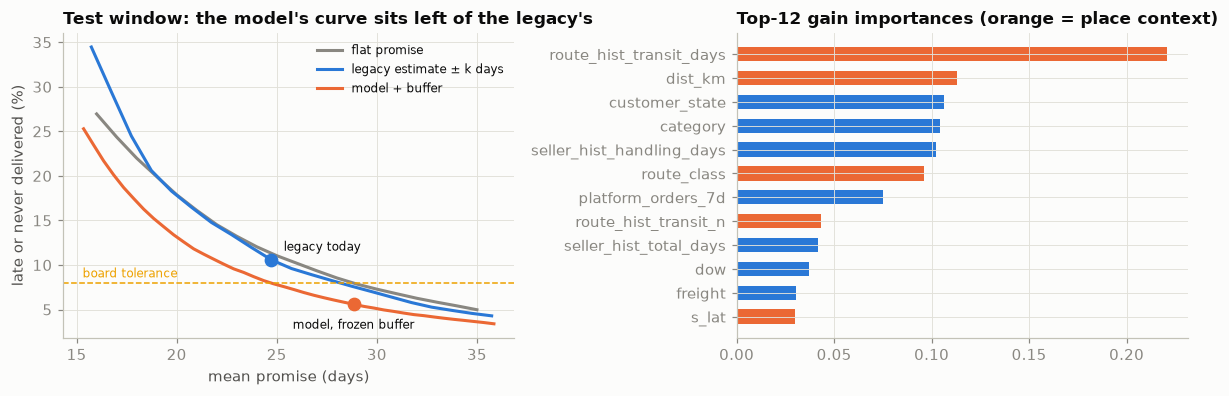

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
ax = axes[0]
for base, lab_, color in [(np.zeros(len(te)), "flat promise", MUTED), (legacy_te, "legacy estimate ± k days", SERIES[0]),
                          (p_te, "model + buffer", SERIES[1])]:
    f = frontier(y_te, base)
    f = f[(f.promise > 15) & (f.promise < 36)]
    ax.plot(f.promise, f.late * 100, "-", lw=2, color=color, label=lab_)
ax.plot([legacy_te.mean()], [legacy_late * 100], "o", ms=8, color=SERIES[0])
ax.annotate("legacy today", (legacy_te.mean(), legacy_late * 100), xytext=(8, 6), textcoords="offset points", fontsize=8)
ax.plot([promise_te.mean()], [(y_te > promise_te).mean() * 100], "o", ms=8, color=SERIES[1])
ax.annotate("model, frozen buffer", (promise_te.mean(), (y_te > promise_te).mean() * 100), xytext=(-40, -16),
            textcoords="offset points", fontsize=8)
ax.axhline(MAX_LATE_RATE * 100, color=SERIES[3], ls="--", lw=1)
ax.text(15.3, MAX_LATE_RATE * 100 + 0.6, "board tolerance", color=SERIES[3], fontsize=8)
ax.set_xlabel("mean promise (days)"); ax.set_ylabel("late or never delivered (%)"); ax.legend(fontsize=8)
ax.set_title("Test window: the model's curve sits left of the legacy's")
ax = axes[1]
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES).sort_values(ascending=False).head(12)
ax.barh(imp.index[::-1], imp.values[::-1] / imp.sum(), color=[SERIES[1] if f in PLACE else SERIES[0] for f in imp.index[::-1]], height=0.6)
ax.set_title("Top-12 gain importances (orange = place context)")
plt.tight_layout()

1. **The model's curve sits left of the legacy's.** At the legacy's late rate it promises 22.4 days instead of 24.7, **2.4 days shorter** (bootstrap 95 % interval 2.33–2.91), with a slightly lower expected 1-star share (11.2 % against 11.5 %). Within a single month the saving is smaller: 0.65 days in March to 3.12 in May, under 2.4 in four months of five. At the board's 8 % the model needs 24.8 days, the legacy 28.7.
2. **No deployable buffer delivers that.** The December buffer (+14.5 days) gives 28.8-day promises at 5.6 % late: 4.1 days *longer* than today. December was slow; spring was fast. The fair comparator is the legacy with its own December buffer (+2 days): 26.7 days at 8.9 % late; to reach 5.6 % it would need 32.7 days. Under the assumed constants the frozen model costs R$ 561 per 1,000 orders against today; the right buffer would earn R$ 750 (at 8 %) to R$ 1,336.
3. **The CI gate passes while the promise grows.** It measures shape (2.39 days saved) and safety (5.6 % ≤ 8 %), not length.

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Four ways to report a better number than the business would get.

**Trap 1 — right-censoring and right-truncation: the newest orders are the fast ones.** On any day, the recent orders that have *already* arrived are the quick ones; the slow ones are still on a lorry. Drop the undelivered and the latest month looks punctual: on the cut, January 2018 showed 0.2 % late (final: 7.2 %); on 1 April, March 2018, the worst month in the data, showed 4.8 % (final: 20.8 %). A pipeline that trains on everything bought before the cut, drops orders in transit and sets the buffer on the newest month picks +4.5 days, then breaks 22.3 % of its promises: nearly three times the tolerance.

In [9]:
def snapshot_view(asof, months):
    rows = []
    for m in months:
        d = o[o.purchased.dt.to_period("M") == pd.Period(m)]
        seen = d.delivered < asof
        rows.append({"seen on": f"{asof:%d %b %Y}", "purchase month": m, "orders": len(d), "delivered by then": seen.mean(),
                     "late rate as seen (undelivered dropped)": (d.y_days[seen] > d.legacy_promise[seen]).mean(),
                     "late rate, final": (d.y_days.fillna(np.inf) > d.legacy_promise).mean()})
    return rows
censor_tbl = pd.DataFrame(snapshot_view(CUT, ["2017-11", "2017-12", "2018-01"]) +
                          snapshot_view(pd.Timestamp("2018-04-01"), ["2018-01", "2018-02", "2018-03"]))
display(censor_tbl.style.format({"orders": "{:,}", "delivered by then": "{:.0%}",
                                 "late rate as seen (undelivered dropped)": "{:.1%}", "late rate, final": "{:.1%}"}).hide(axis="index"))

# naive pipeline: every order bought before the cut, undelivered ones dropped; buffer set on the latest month
naive = o[o.purchased < CUT]
y_nv = days_asof(naive, CUT); keep = np.isfinite(y_nv)
m_naive = fit(FEATURES, naive[keep], y_nv[keep])
jan = (naive.purchased >= VALID_END).values & keep
buf_naive = buffer_for(y_nv[jan], m_naive.predict(naive[jan][FEATURES]), MAX_LATE_RATE)
prom_naive = np.ceil(m_naive.predict(te[FEATURES]) + buf_naive)
trap1 = {"naive": f"buffer +{buf_naive:.1f} → late {(y_te > prom_naive).mean():.1%} at {prom_naive.mean():.1f} days",
         "honest": f"buffer +{BUFFER:.1f} → late {(y_te > promise_te).mean():.1%} at {promise_te.mean():.1f} days"}
delivered_only = np.isfinite(y_te)
print(f"Trap 1 · naive pipeline ({keep.sum():,} training orders, {int((~keep).sum()):,} undelivered dropped): {trap1['naive']} · "
      f"honest: {trap1['honest']}")
print(f"         legacy late rate on the test window counting only delivered orders: "
      f"{(y_te[delivered_only] > legacy_te[delivered_only]).mean():.1%} (honest, never-delivered counted: {legacy_late:.1%})")
# ... and right-truncation: after June 2018 an order is in the extract only if its review existed by the cut-off
late_buys = orders_all[(orders_all.purchased >= WINDOW_END) & (orders_all.purchased < EXTRACT_END)
                       & ~orders_all.status.isin(["canceled", "unavailable"])]
after_end = late_buys.estimated >= EXTRACT_END
open_at_end = late_buys.delivered.isna() | (late_buys.delivered >= EXTRACT_END)
daily = late_buys.groupby(late_buys.purchased.dt.normalize()).size()
print(f"Trap 1 · Jul–Aug 2018 purchases: promised after {EXTRACT_END - pd.Timedelta(days=1):%d %b} → {open_at_end[after_end].mean():.1%} "
      f"undelivered at the cut-off (n = {int(after_end.sum()):,}); promised before → {open_at_end[~after_end].mean():.1%} "
      f"(n = {int((~after_end).sum()):,}) · orders a day: {daily.loc[:'2018-08-10'].mean():.0f} until 10 Aug, "
      f"{daily.loc['2018-08-24':].mean():.0f} from 24 Aug · mean promise {(late_buys.estimated - late_buys.purchased.dt.normalize()).dt.days.mean():.1f} days "
      f"(Jan–Jun 2018: {o.loc[o.purchased >= VALID_END, 'legacy_promise'].mean():.1f})")

seen on,purchase month,orders,delivered by then,late rate as seen (undelivered dropped),"late rate, final"
01 Feb 2018,2017-11,"7,422",98%,12.2%,14.0%
01 Feb 2018,2017-12,"5,620",97%,6.4%,9.2%
01 Feb 2018,2018-01,"7,187",58%,0.2%,7.2%
01 Apr 2018,2018-01,"7,187",98%,5.4%,7.2%
01 Apr 2018,2018-02,"6,625",94%,9.8%,15.0%
01 Apr 2018,2018-03,"7,168",49%,4.8%,20.8%


Trap 1 · naive pipeline (47,527 training orders, 4,037 undelivered dropped): buffer +4.5 → late 22.3% at 16.0 days · honest: buffer +14.5 → late 5.6% at 28.8 days
         legacy late rate on the test window counting only delivered orders: 9.2% (honest, never-delivered counted: 10.6%)
Trap 1 · Jul–Aug 2018 purchases: promised after 31 Aug → 0.1% undelivered at the cut-off (n = 2,000); promised before → 1.9% (n = 10,654) · orders a day: 225 until 10 Aug, 59 from 24 Aug · mean promise 18.0 days (Jan–Jun 2018: 25.1)


In evaluation it flatters the incumbent (9.2 % late instead of 10.6 %). The extract has the stronger form, **truncation**: it ends with the last review on 31 Aug 2018, and an order seems to appear only once its review exists (at delivery or on the promised date). July–August orders promised after 31 August are there only if delivered (0.1 % open, against 1.9 % for those promised earlier), daily volume falls from 225 to 59, and the mean promise looks like 18.0 days instead of 25.1. Slow orders are not late there; they are absent. Hence the window stops at June 2018.

**Trap 2 — features that exist only after checkout.** Hand-off, approval delay and review fields sit beside the purchase time. With them, MAE falls to 1.07 days and the model "saves" 10.9 days, 79 % of its gain on those four columns; none exists when `POST /promise` is called. The review is the sneakiest: one written before delivery flags lateness (5.4 % of orders; 95 % late).

**Trap 3 — the random split.** Shuffle Jan 2017 – Jun 2018 70/30 and MAE drops from 5.62 to 4.49 days, days saved rise from 2.4 to 2.6. The row changes three things at once (split, final labels with never-delivered set to 120 days, test set); the likely cause, learning each month's weather from its own orders, is not isolated here (C1).

**Trap 4 — the legacy estimate as a feature (a decision, not a leak).** It is known at checkout and ranks second of 32 features by gain, yet makes the test window *worse* (MAE 5.70 against 5.62; 2.3 against 2.4 days saved). Its relation to delivery drifts: it was shortest for March 2018 purchases (22.7 days), when the late rate peaked (20.8 %; median delivery 13 days, against 14 in February), and longest for June (28.4), when parcels were fastest (8). And it is the output this system replaces: once deployed, the column would be the model's own output (a feedback loop). It stays the benchmark.

In [10]:
# Trap 2: features that only exist after the purchase
o["approval_hours"] = (o.approved - o.purchased).dt.total_seconds() / 3600
o["carrier_days"] = (o.carrier - o.purchased).dt.total_seconds() / 86400
o["review_lead_days"] = (o.review_created - o.pday).dt.days
POST = ["approval_hours", "carrier_days", "review_score", "review_lead_days"]
tr, te = o[o.purchased < TRAIN_END], o[o.purchased >= CUT]
m_post = fit(FEATURES + POST, tr, y_tr)
p_post = m_post.predict(te[FEATURES + POST])

# Trap 3: a random 70/30 split of the whole window, final labels
y_all = days_asof(o, EXTRACT_END)
is_tr = rng.random(len(o)) < 0.7
m_rand = fit(FEATURES, o[is_tr], np.where(np.isfinite(y_all), y_all, 120)[is_tr])
p_rand = m_rand.predict(o.loc[~is_tr, FEATURES])
y_rt, leg_rt = y_all[~is_tr], o.legacy_promise.values[~is_tr].astype(float)
late_rt = float((y_rt > leg_rt).mean())

# Trap 4: Olist's own estimate as a feature
m_leg = fit(FEATURES + ["legacy_promise"], tr, y_tr)
p_leg = m_leg.predict(te[FEATURES + ["legacy_promise"]])

traps = pd.DataFrame([
    ["1 · right-censoring", "late rate on test at the chosen buffer", trap1["naive"], trap1["honest"]],
    ["2 · features known after purchase", "MAE · days saved at the legacy's late rate",
     f"{mae(y_te, p_post):.2f} · {saved(y_te, p_post, legacy_te):.1f}", f"{mae(y_te, p_te):.2f} · {days_saved:.1f}"],
    ["3 · random split", "MAE · days saved at the legacy's late rate",
     f"{mae(y_rt, p_rand):.2f} · {saved(y_rt, p_rand, leg_rt):.1f}", f"{mae(y_te, p_te):.2f} · {days_saved:.1f}"],
    ["4 · legacy estimate as a feature", "MAE · days saved at the legacy's late rate",
     f"{mae(y_te, p_leg):.2f} · {saved(y_te, p_leg, legacy_te):.1f}", f"{mae(y_te, p_te):.2f} · {days_saved:.1f}"],
], columns=["trap", "metric (test window)", "naive", "honest"]).set_index("trap")
display(traps)
post_imp = pd.Series(m_post.booster_.feature_importance("gain"), index=FEATURES + POST)
print(f"Trap 2 · share of gain on the post-purchase columns: {post_imp[POST].sum() / post_imp.sum():.0%} · "
      f"reviews written before the parcel arrived: {(o.review_created < o.delivered.dt.normalize()).mean():.1%} of orders, "
      f"{(o.outcome[o.review_created < o.delivered.dt.normalize()] == 'late').mean():.0%} of them late")
leg_imp = pd.Series(m_leg.booster_.feature_importance("gain"), index=FEATURES + ["legacy_promise"]).rank(ascending=False)
print(f"Trap 4 · legacy_promise ranks #{int(leg_imp['legacy_promise'])} of {len(leg_imp)} by gain · mean legacy promise by "
      "purchase month: " + " · ".join(f"{m:%b %y} {v:.1f}" for m, v in
                                       o.groupby(o.purchased.dt.to_period("M").dt.to_timestamp()).legacy_promise.mean().iloc[-6:].items())
      + " · median delivery days: " + " · ".join(f"{m:%b %y} {v:.0f}" for m, v in
                                       o.groupby(o.purchased.dt.to_period("M").dt.to_timestamp()).y_days.median().iloc[-6:].items()))

,metric (test window),naive,honest
trap,,,
1 · right-censoring,late rate on test at the chosen buffer,buffer +4.5 → late 22.3% at 16.0 days,buffer +14.5 → late 5.6% at 28.8 days
2 · features known after purchase,MAE · days saved at the legacy's late rate,1.07 · 10.9,5.62 · 2.4
3 · random split,MAE · days saved at the legacy's late rate,4.49 · 2.6,5.62 · 2.4
4 · legacy estimate as a feature,MAE · days saved at the legacy's late rate,5.70 · 2.3,5.62 · 2.4


Trap 2 · share of gain on the post-purchase columns: 79% · reviews written before the parcel arrived: 5.4% of orders, 95% of them late
Trap 4 · legacy_promise ranks #2 of 32 by gain · mean legacy promise by purchase month: Jan 18 27.0 · Feb 18 25.2 · Mar 18 22.7 · Apr 18 24.3 · May 18 23.5 · Jun 18 28.4 · median delivery days: Jan 18 12 · Feb 18 14 · Mar 18 13 · Apr 18 9 · May 18 9 · Jun 18 8


# Part C — Productionise it

*Sections 6–10: this is your assignment.*

## 6 · After the cut: the network's weather moves the promise

*Part C · Productionise · what your monitoring plan must catch (C5); reuse `psi` and `psi_cat`.*

Delivery speed is the state of a network of sellers, carriers and the post, and it moves. As in Task 02, inputs can be watched at checkout; the late rate only once a parcel arrives or its promise passes.

late rate by purchase month: Oct 17 5.6% · Nov 17 14.0% · Dec 17 9.2% · Jan 18 7.2% · Feb 18 15.0% · Mar 18 20.8% · Apr 18 6.2% · May 18 7.7% · Jun 18 1.9%
peak weeks: 26 Nov 2017 18.9% · 04 Mar 2018 27.6% · median delivery days, Jun 17 11 · Mar 18 13 · Jun 18 8


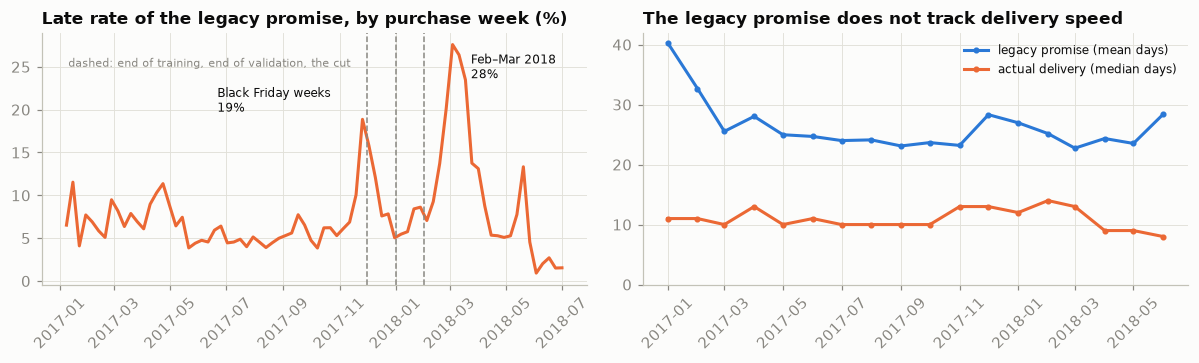

In [11]:
weekly = o.assign(late=(y_final > o.legacy_promise.values)).set_index("purchased").resample("W").agg(
    late=("late", "mean"), n=("order_id", "size"))
monthly = o.groupby(o.purchased.dt.to_period("M")).agg(promise=("legacy_promise", "mean"), actual=("y_days", "median"),
                                                        late=("outcome", lambda s: (s != "on time").mean()))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.plot(weekly.index, weekly.late * 100, "-", lw=2, color=SERIES[1])
for x in [TRAIN_END, VALID_END, CUT]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
ax.text(pd.Timestamp("2017-01-10"), 25, "dashed: end of training, end of validation, the cut", color=MUTED, fontsize=7)
bf = weekly.late.loc["2017-11-15":"2017-12-15"].idxmax(); sp = weekly.late.loc["2018-02-01":"2018-04-01"].idxmax()
ax.annotate(f"Black Friday weeks\n{weekly.late[bf]:.0%}", (bf, weekly.late[bf] * 100), xytext=(-95, 5), textcoords="offset points", fontsize=8)
ax.annotate(f"Feb–Mar 2018\n{weekly.late[sp]:.0%}", (sp, weekly.late[sp] * 100), xytext=(12, -22), textcoords="offset points", fontsize=8)
ax.set_title("Late rate of the legacy promise, by purchase week (%)"); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
t_ = monthly.index.to_timestamp()
ax.plot(t_, monthly.promise, "-o", ms=3, lw=2, color=SERIES[0], label="legacy promise (mean days)")
ax.plot(t_, monthly.actual, "-o", ms=3, lw=2, color=SERIES[1], label="actual delivery (median days)")
ax.set_ylim(0, None); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=45)
ax.set_title("The legacy promise does not track delivery speed")
plt.tight_layout()
print("late rate by purchase month: " + " · ".join(f"{m:%b %y} {v:.1%}" for m, v in monthly.late.items() if m >= pd.Period("2017-10")))
print(f"peak weeks: {bf:%d %b %Y} {weekly.late[bf]:.1%} · {sp:%d %b %Y} {weekly.late[sp]:.1%} · median delivery days, "
      + " · ".join(f"{m:%b %y} {v:.0f}" for m, v in monthly.actual.items() if m in [pd.Period("2017-06"), pd.Period("2018-03"), pd.Period("2018-06")]))

Now run the frozen model and buffer month by month beside **recalibrated**, which keeps the model but re-chooses the buffer monthly on the newest matured month (two months back).

,orders,recal buffer,bias (days),PSI platform volume,PSI seller state,PSI category,PSI predicted days
month,,,,,,,
2017-12,"5,620",+8.0,+2.13,5.74,0.020,0.125,0.20
2018-01,"7,187",+14.5,+0.21,5.54,0.041,0.171,0.32
2018-02,"6,625",+14.5,+2.36,12.43,0.100,0.214,0.52
2018-03,"7,168",+12.0,+1.73,12.43,0.079,0.141,0.57
2018-04,"6,919",+17.5,-2.34,12.43,0.064,0.203,0.44
2018-05,"6,833",+18.5,-2.08,5.81,0.110,0.251,0.34
2018-06,"6,142",+6.0,-3.70,5.60,0.105,0.304,0.27


Feb–Jun 2018, order-weighted: legacy: late 10.6%, promise 24.7 days · frozen: late 5.6%, promise 28.8 days · recalibrated: late 6.1%, promise 28.2 days
platform orders in the previous 7 days: training median 937, 95th percentile 2641; test median 1623 · training orders with ≥ 1,600: 8.3%, all bought 24 Nov – 30 Nov 2017


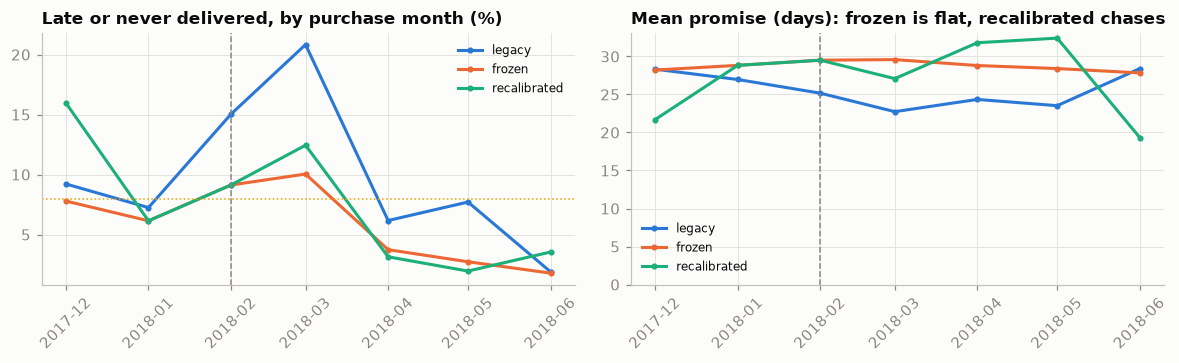

In [12]:
def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

def psi_cat(ref, cur):
    r = ref.value_counts(normalize=True); c = cur.value_counts(normalize=True)
    idx = r.index.union(c.index); r = r.reindex(idx).fillna(0) + 1e-4; c = c.reindex(idx).fillna(0) + 1e-4
    return float(np.sum((c - r) * np.log(c / r)))

o["p_frozen"] = model.predict(o[FEATURES])
o["month"] = o.purchased.dt.to_period("M")
ref = o[o.purchased < TRAIN_END]
rows = []
for mth in pd.period_range("2017-12", "2018-06", freq="M"):
    d = o[o.month == mth]; y = days_asof(d, EXTRACT_END)
    cal = o[o.month == mth - 2]                                     # the newest month whose labels have matured
    k_recal = buffer_for(days_asof(cal, mth.to_timestamp()), cal.p_frozen.values, MAX_LATE_RATE)
    pf, pr = np.ceil(d.p_frozen + BUFFER), np.ceil(d.p_frozen + k_recal)
    rows.append({"month": mth, "orders": len(d),
                 "legacy late": (y > d.legacy_promise.values).mean(), "frozen late": (y > pf).mean(), "recalibrated late": (y > pr).mean(),
                 "legacy promise": d.legacy_promise.mean(), "frozen promise": pf.mean(), "recalibrated promise": pr.mean(),
                 "recal buffer": k_recal, "bias (days)": float(np.mean((y - d.p_frozen)[np.isfinite(y)])),
                 "PSI platform volume": psi(ref.platform_orders_7d, d.platform_orders_7d),
                 "PSI seller state": psi_cat(ref.seller_state, d.seller_state), "PSI category": psi_cat(ref.category, d.category),
                 "PSI predicted days": psi(ref.p_frozen, d.p_frozen)})
mon = pd.DataFrame(rows).set_index("month")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
t_ = mon.index.to_timestamp()
for ax, kind, unit in [(axes[0], "late", 100), (axes[1], "promise", 1)]:
    for c, color in [("legacy", SERIES[0]), ("frozen", SERIES[1]), ("recalibrated", SERIES[2])]:
        ax.plot(t_, mon[f"{c} {kind}"] * unit, "-o", ms=3, lw=2, color=color, label=c)
    ax.axvline(CUT, color=MUTED, ls="--", lw=1); ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
axes[0].axhline(MAX_LATE_RATE * 100, color=SERIES[3], ls=":", lw=1)
axes[0].set_title("Late or never delivered, by purchase month (%)")
axes[1].set_title("Mean promise (days): frozen is flat, recalibrated chases"); axes[1].set_ylim(0, None)
plt.tight_layout()
display(mon[["orders", "recal buffer", "bias (days)", "PSI platform volume", "PSI seller state", "PSI category", "PSI predicted days"]]
        .style.format({"orders": "{:,}", "recal buffer": "{:+.1f}", "bias (days)": "{:+.2f}", "PSI platform volume": "{:.2f}",
                       "PSI seller state": "{:.3f}", "PSI category": "{:.3f}", "PSI predicted days": "{:.2f}"}))
after = mon.loc[pd.Period("2018-02"):]
w = after.orders / after.orders.sum()
print("Feb–Jun 2018, order-weighted: " + " · ".join(
    f"{c}: late {(after[f'{c} late'] * w).sum():.1%}, promise {(after[f'{c} promise'] * w).sum():.1f} days"
    for c in ["legacy", "frozen", "recalibrated"]))
busy = ref[ref.platform_orders_7d >= 1600]
print(f"platform orders in the previous 7 days: training median {ref.platform_orders_7d.median():.0f}, 95th percentile "
      f"{ref.platform_orders_7d.quantile(0.95):.0f}; test median {te.platform_orders_7d.median():.0f} · training orders with ≥ 1,600: "
      f"{len(busy) / len(ref):.1%}, all bought {busy.purchased.min():%d %b} – {busy.purchased.max():%d %b %Y}")

- **Two surges and a speed-up.** 14.0 % late for November 2017 purchases (18.9 % in the week ending 26 Nov, Black Friday week), 15.0 % and 20.8 % for February and March 2018 (27.6 % in the week ending 4 Mar), then 1.9 % in June. Median delivery: 11 days (June 2017), 13 (March 2018), 8 (June 2018).
- **Frozen is safe and slow; recalibrated chases.** The frozen model's bias swings from +2.4 days in February to −3.7 in June. Recalibration does not help (28.2 days at 6.1 % late against 28.8 at 5.6 %): it answers the weather of two months earlier, +17.5 and +18.5 days in April and May, after the surge had ended.
- **The loudest input drift is a feature artefact.** `platform_orders_7d` has a PSI of 5.5–12.4 every month: in training a 1,600-order week happened only on 24–30 November 2017 (median 937); in 2018 it is ordinary (median 1,623), and the model may read it as a peak (record it in the model card and watch it in C5's plan). Category mix drifts too (PSI 0.30 by June); seller state barely (at most 0.11).

For C5: estimate the late rate from **partial labels** (an order past its promise and undelivered is already late), cutting the delay from weeks to days, and version the buffer apart from the model.

## 7 · The knowledge base: places, sellers and categories

*Part C · Productionise · the KB behind the place features (Part B material, kept here for contiguity); E1 extends it, S1 uses `wismo_context`.*

Checkout, the seller portal and customer service all need the place reference data behind Section 3, so it belongs in a knowledge layer with an owner, competency questions and validation (Sessions 07–09). Ours: *Where do sellers ship from? Which categories lack an English name? Does each seller's declared state match its postcode? Which route class is this order?* Classes map to schema.org, categories to SKOS concepts (PT and EN labels); orders stay in the warehouse.

In [13]:
OL, SDO = Namespace("https://example.org/olist/"), Namespace("https://schema.org/")
kg = Graph(); kg.bind("ol", OL); kg.bind("schema", SDO); kg.bind("skos", SKOS)
# ---- the ontology: our classes mapped to schema.org (instances of Order, Item, Product, Customer stay in the warehouse) ----
MAPPING = {"Order": SDO.Order, "OrderItem": SDO.OrderItem, "Product": SDO.Product, "Seller": SDO.Organization,
           "Customer": SDO.Person, "ZipPrefix": SDO.Place, "State": SDO.State, "Region": SDO.AdministrativeArea,
           "Category": SKOS.Concept}
for cls, sup in MAPPING.items():
    kg.add((OL[cls], RDF.type, RDFS.Class)); kg.add((OL[cls], RDFS.subClassOf, sup))
for p, dom, rng_ in [("orderedItem", "Order", "OrderItem"), ("product", "OrderItem", "Product"), ("seller", "OrderItem", "Seller"),
                     ("category", "Product", "Category"), ("customer", "Order", "Customer"), ("location", "Seller", "ZipPrefix"),
                     ("location", "Customer", "ZipPrefix"), ("containedInPlace", "ZipPrefix", "State"),
                     ("containedInPlace", "State", "Region")]:
    kg.add((SDO[p], RDFS.domain, OL[dom])); kg.add((SDO[p], RDFS.range, OL[rng_]))
# ---- reference data: regions, states, categories (seeded by the PT→EN file), sellers and their zip prefixes ----
for reg, states in REGIONS.items():
    r = OL["region/" + reg.replace("-", "")]; kg.add((r, RDF.type, OL.Region)); kg.add((r, SDO.name, Literal(reg)))
    for s in states.split():
        st = OL["state/" + s]; kg.add((st, RDF.type, OL.State)); kg.add((st, SDO.containedInPlace, r))
for _, c in categories.iterrows():
    u = OL["category/" + c.category_pt]; kg.add((u, RDF.type, OL.Category))
    kg.add((u, SKOS.prefLabel, Literal(c.category_pt, lang="pt")))
    if isinstance(c.category_en, str):
        kg.add((u, SKOS.prefLabel, Literal(c.category_en, lang="en")))
for _, s in sellers.iterrows():
    u, z = OL["seller/" + s.seller_id], OL[f"zip/{s.zip:05d}"]
    kg.add((u, RDF.type, OL.Seller)); kg.add((u, SDO.location, z)); kg.add((u, OL.declaredState, OL["state/" + s.seller_state]))
    kg.add((z, RDF.type, OL.ZipPrefix))
    if pd.notna(s.lat):
        kg.add((z, SDO.latitude, Literal(round(float(s.lat), 4), datatype=XSD.decimal)))
        kg.add((z, SDO.longitude, Literal(round(float(s.lng), 4), datatype=XSD.decimal)))
        kg.add((z, SDO.containedInPlace, OL["state/" + s.zip_state]))
print(f"knowledge base: {len(kg):,} triples · {len(MAPPING)} classes mapped to schema.org / SKOS · "
      f"{len(set(kg.subjects(RDF.type, OL.ZipPrefix))):,} seller zip prefixes")

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix ol: <https://example.org/olist/> .
@prefix schema: <https://schema.org/> . @prefix skos: <http://www.w3.org/2004/02/skos/core#> .
ol:CategoryShape a sh:NodeShape ; sh:targetClass ol:Category ;
  sh:property [ sh:path skos:prefLabel ; sh:languageIn ("pt" "en") ; sh:uniqueLang true ; sh:minCount 2 ;
                sh:message "category needs a pt and an en label" ] .
ol:SellerShape a sh:NodeShape ; sh:targetClass ol:Seller ;
  sh:property [ sh:path schema:location ; sh:minCount 1 ; sh:maxCount 1 ; sh:class ol:ZipPrefix ] ;
  sh:property [ sh:path ol:declaredState ; sh:minCount 1 ; sh:class ol:State ] ;
  sh:property [ sh:path ( schema:location schema:containedInPlace ) ; sh:equals ol:declaredState ;
                sh:message "declared state not confirmed by the seller's zip prefix" ] .
ol:ZipShape a sh:NodeShape ; sh:targetClass ol:ZipPrefix ;
  sh:property [ sh:path schema:latitude ; sh:minCount 1 ; sh:message "zip prefix has no coordinates" ] ;
  sh:property [ sh:path schema:containedInPlace ; sh:minCount 1 ; sh:maxCount 1 ; sh:class ol:State ;
                sh:message "zip prefix is not placed in a state" ] .
ol:StateShape a sh:NodeShape ; sh:targetClass ol:State ;
  sh:property [ sh:path schema:containedInPlace ; sh:minCount 1 ; sh:maxCount 1 ; sh:class ol:Region ] .
"""
conforms, vg, _ = pyshacl.validate(kg, shacl_graph=Graph().parse(data=SHAPES, format="turtle"), inference="none")
SH = Namespace("http://www.w3.org/ns/shacl#")
viol = pd.DataFrame([{"message": str(vg.value(r, SH.resultMessage))[:70], "focus": str(vg.value(r, SH.focusNode)).split("/")[-1][:14]}
                     for r in vg.subjects(RDF.type, SH.ValidationResult)])
print(f"SHACL conforms: {conforms} · {len(viol)} validation results on {viol.focus.nunique()} nodes")
display(viol.groupby("message").agg(nodes=("focus", "nunique"), examples=("focus", lambda s: ", ".join(s.unique()[:2]))))
unplaced = sellers.zip_state.isna()
print(f"of the sellers flagged for their state: {int((~unplaced & (sellers.zip_state != sellers.seller_state)).sum())} contradict "
      f"their zip prefix, {int(unplaced.sum())} sit on a prefix with no coordinates")

knowledge base: 18,564 triples · 9 classes mapped to schema.org / SKOS · 2,246 seller zip prefixes


SHACL conforms: False · 93 validation results on 51 nodes


,nodes,examples
message,,
category needs a pt and an en label,2,"portateis_cozi, pc_gamer"
declared state not confirmed by the seller's zip prefix,42,"8060d731897e33, 52b53f7061969f"
zip prefix has no coordinates,7,"37708, 07412"
zip prefix is not placed in a state,7,"37708, 07412"


of the sellers flagged for their state: 35 contradict their zip prefix, 7 sit on a prefix with no coordinates


In [14]:
CQ = {
    "CQ1 · sellers by region": """SELECT ?region (COUNT(?s) AS ?sellers) WHERE { ?s a ol:Seller ; schema:location/schema:containedInPlace/schema:containedInPlace ?r . ?r schema:name ?region } GROUP BY ?region ORDER BY DESC(?sellers)""",
    "CQ2 · categories without an English label": """SELECT ?c WHERE { ?c a ol:Category . FILTER NOT EXISTS { ?c skos:prefLabel ?l . FILTER(lang(?l) = "en") } }""",
}
for name, q in CQ.items():
    res_q = [tuple(str(v).split("/")[-1] for v in row) for row in kg.query(q, initNs={"ol": OL, "schema": SDO, "skos": SKOS})]
    print(f"{name}: {res_q}")
# the place context in Section 3 must equal what the KB serves (seller → zip → state → region)
q = """SELECT ?s ?region WHERE { ?s a ol:Seller ; ol:declaredState/schema:containedInPlace/schema:name ?region }"""
kb_region = {str(s).split("/")[-1]: str(r) for s, r in kg.query(q, initNs={"ol": OL, "schema": SDO})}
same = (o.seller_id.map(kb_region).fillna("unknown") == o.seller_region.astype(str)).mean()
print(f"seller_region from the KB matches the feature table for {same:.1%} of orders")

# the ablation: without and with the seller-region context
m_flat = fit(ORDER, tr, y_tr)
p_flat_va, p_flat_te = m_flat.predict(va[ORDER]), m_flat.predict(te[ORDER])
def ablation_row(name, pv, pt):
    b = buffer_for(y_va, pv, MAX_LATE_RATE); pr = np.ceil(pt + b)
    row = {"context": name, "MAE test": mae(y_te, pt), "days saved at legacy's late rate": saved(y_te, pt, legacy_te),
           "frozen buffer": b, "late (frozen)": (y_te > pr).mean(), "promise (frozen)": pr.mean()}
    for rc in ["same state", "same region", "inter-region"]:
        msk = (te.route_class == rc).values
        row[f"MAE · {rc}"] = mae(y_te[msk], pt[msk])
    return row
abl = pd.DataFrame([ablation_row("order only", p_flat_va, p_flat_te),
                    ablation_row("+ seller-region context (KB)", p_va, p_te)]).set_index("context")
display(abl.style.format({c: "{:.2f}" for c in abl.columns} | {"late (frozen)": "{:.1%}", "frozen buffer": "{:+.1f}", "promise (frozen)": "{:.1f}"}))
print("test orders by route class: " + " · ".join(f"{k} {v:.0%}" for k, v in te.route_class.value_counts(normalize=True).items()))

CQ1 · sellers by region: [('Southeast', '2263'), ('South', '687'), ('Center-West', '78'), ('Northeast', '56'), ('North', '4')]
CQ2 · categories without an English label: [('pc_gamer',), ('portateis_cozinha_e_preparadores_de_alimentos',)]


seller_region from the KB matches the feature table for 100.0% of orders


,MAE test,days saved at legacy's late rate,frozen buffer,late (frozen),promise (frozen),MAE · same state,MAE · same region,MAE · inter-region
context,,,,,,,,
order only,5.74,2.10,+15.0,5.6%,29.1,4.05,6.97,6.62
+ seller-region context (KB),5.62,2.39,+14.5,5.6%,28.8,3.38,7.39,6.68


test orders by route class: same state 37% · inter-region 37% · same region 26%


In [15]:
# Context for the "where is my order?" assistant (task S1): facts from the order tables + a SYNTHETIC policy handbook
HANDBOOK = {   # synthetic, written for this course; not Olist's policy
    "P1": "A promise is the delivery date shown at checkout. It is not changed after purchase.",
    "P2": "If the promised date has passed and the parcel has not arrived, apologise, give the new estimate and open a carrier claim.",
    "P3": "Seven days after a broken promise the customer may cancel for a full refund, freight included.",
    "P4": "Orders paid by boleto are confirmed when the payment clears; the promise counts from purchase.",
    "P5": "Never state a carrier's internal reason for delay; say 'in transit' unless the claim is resolved.",
}
def wismo_context(order_id: str, asof: pd.Timestamp) -> dict:
    r = o.set_index("order_id").loc[order_id]
    promised = r.pday + pd.Timedelta(days=int(r.legacy_promise))
    delivered = pd.notna(r.delivered) and r.delivered < asof
    days_over = (asof.normalize() - promised).days
    rules = ["P1"] + (["P2"] if days_over > 0 and not delivered else []) + (["P3"] if days_over >= 7 and not delivered else []) \
            + (["P4"] if r.pay_type == "boleto" else [])
    return {"order": order_id[:8] + "…", "as of": f"{asof:%Y-%m-%d}", "promised date": f"{promised:%Y-%m-%d}",
            "handed to carrier": f"{r.carrier:%Y-%m-%d}" if pd.notna(r.carrier) and r.carrier < asof else "not yet",
            "delivered": f"{r.delivered:%Y-%m-%d}" if delivered else "not yet", "days past promise": max(days_over, 0),
            "model ETA (median days from purchase)": round(float(r.p_frozen), 1), "policy clauses": rules}
example = te[(te.outcome == "late") & te.carrier.notna()].iloc[0]
print(wismo_context(example.order_id, example.pday + pd.Timedelta(days=int(example.legacy_promise) + 8)))

{'order': 'f31535f2…', 'as of': '2018-03-13', 'promised date': '2018-03-05', 'handed to carrier': '2018-02-02', 'delivered': 'not yet', 'days past promise': 8, 'model ETA (median days from purchase)': 16.9, 'policy clauses': ['P1', 'P2', 'P3']}


- **SHACL earns its keep on the first run:** 2 categories without an English label, 7 seller zip prefixes with no coordinates, and 42 sellers whose declared state their postcode does not confirm (35 contradict it; 7 sit on unplaced prefixes). Each is a ticket for the data owner.
- **One definition, served once:** the KB's seller region matches the feature table for 100 % of orders; 2,263 sellers are in the Southeast, 4 in the North.
- **The ablation.** With the seller-region context the model saves 2.39 days at the legacy's late rate; without it, 2.10. MAE improves from 5.74 to 5.62 days, but unevenly: same-state routes gain (4.05 → 3.38 days), same-region ones lose (6.97 → 7.39). About 0.3 day, from one seed and one cut (E1).
- **Context for the assistant:** order facts as of a date, the ETA and **synthetic** handbook clauses chosen by rule; no customer data (task S1).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The answer to the board is "about 2.4 days (0.65–3.1 within a month), if the buffer keeps up with the network"; no buffer tested here did. This is what must run for it to come true.

| Spine | In this project (updated with what this notebook found) |
|---|---|
| Package and container (S02–S03) | `src/delivery_promise/` (as-of features, censoring rule, promise); `POST /promise` returns a date with model and buffer versions; compose with Postgres. |
| Monitoring (S04) | *Now:* PSI on platform volume (5.5–12.4: a feature artefact, documented in the model card), category mix (0.30 by June), seller state (≤ 0.11), predicted days (0.20–0.57). *Later:* weekly late rate from partial labels; the median's bias (+2.4 to −3.7 days). Alert at a partial-label late rate above 8 % for two weeks. |
| CI/CD gate (S05) | Frozen Feb–Jun 2018 holdout (33,687 orders, SHA-256 printed in Section 4): days saved at the legacy's late rate ≥ 1.0 (now 2.39), frozen late rate ≤ 8 % (now 5.6 %). Both pass with a promise 4.1 days longer than today's: add a mean-promise check. |
| MLflow tracking and registry (S06) | Cut date, censoring rule, `ETA_QUANTILE`, buffer, holdout fingerprint; model and buffer versioned separately, `champion` alias. |
| Offline / online training and serving | Online promise at checkout; monthly refit with labels as of the refit day; weekly buffer recalibration from partial labels; ADR on a peak-season buffer. |
| Data and model drift | Black Friday 2017 (14.0 %), Feb–Mar 2018 (15.0 %, 20.8 %), June 2018 (1.9 %); a legacy estimate moving against the network; 2018 volume read as a peak; truncation after June 2018. |
| Knowledge base and context (S07–S09) | 18,564 triples (regions, states, seller zip prefixes, sellers, 73 SKOS categories) on schema.org; SHACL flags 2 untranslated categories, 7 unplaced prefixes, 42 unconfirmed seller states. Ablation: seller-region context worth 0.3 day. |
| GenAI and context engineering (S10–S11) | "Where is my order?" assistant over the context pack (order facts, ETA, synthetic clauses P1–P5); golden set of real order states; no customer data in prompts. |
| Governance | CC BY-NC-SA 4.0, teaching only; re-identification risk from state, timestamps and basket; review text never printed; copy risk high (905 public Kaggle notebooks, the lecture's example). The AI Act position is a question for E3. |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with tests.** The censoring rule and the window end as tested functions; `tests/test_features.py` failing if a feature uses an event after the purchase; post-purchase columns kept out by an allow-list; the Trap 4 decision recorded.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `MAX_LATE_RATE` (5–12 %), `COST_LATE_BRL` and `VALUE_PER_DAY_BRL`; choose the buffer by cost instead of tolerance and compare; the ADR names who signs off the tolerance and what the 1-star mapping assumes.
- **C4 — Package, container and gate.** `POST /promise` in a container; `make ci` gating on the frozen, fingerprinted Feb–Jun 2018 holdout: days saved, frozen late rate, and a mean-promise check that would have stopped the 28.8-day promise (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs with cut date, censoring rule, buffer and holdout fingerprint; a `champion` alias; a model card; a monitoring plan with the partial-label late rate, PSI thresholds, and refit and recalibration triggers (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation, done properly.** Extend the KB from your competency questions, run SHACL in CI, measure with and without the place context over several seeds and cuts (Sessions 07–09).
- **E2 — Fairness by region.** Promise length and late rate by customer region, legacy against your operating point: is one national tolerance fair if it means longer promises for the North and Northeast?
- **E3 — Governance and licence.** Licence terms, re-identification risk, and where a promise service and a chatbot sit under the EU AI Act and consumer law: cite what you can, ask counsel the rest.
- **E4 — A late-order watch list without a new model.** Use the given promise model's prediction and the days already elapsed to flag placed orders running past their median; size the daily list against a contact capacity you state and say what the customer is told.

### Stretch

- **S1 — The "where is my order?" assistant.** From the context pack and handbook only: versioned prompt, structured output (status, new estimate, clauses), a golden set of 50 real order states whose dates and clauses must be reproduced exactly, injection tests through order fields, cost per answer (Sessions 10–11).
- **S2 — Recalibration with partial labels.** Re-choose the buffer weekly through Feb–Jun 2018 using only what was known each week; compare with Section 6's buffers.
- **S3 — Streaming serving and its cost.** Stream delivery events (Kafka or a Postgres outbox) into the partial-label monitor; state the checkout latency budget and the cost per 1,000 promises.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; `data/` not committed; no review text or customer IDs in the repository or logs
- [ ] `README.md` states window, cut date, censoring rule and data source (Kaggle, CC BY-NC-SA 4.0, teaching only)
- [ ] Forward evaluation with labels as known on the training day; as-of and censoring tests in the suite
- [ ] Operating point on the frontier, with the ADR (tolerance, constants, sign-off)
- [ ] CI with the holdout gate; model and buffer registered; model card; monitoring plan on partial labels
- [ ] One-page board recommendation: how many days, at what late rate, under which assumptions
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `lightgbm`, `rdflib`, `pyshacl`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`).
- Olist (2018). *Brazilian E-Commerce Public Dataset by Olist.* Kaggle, CC BY-NC-SA 4.0.
- Koenker, R., Bassett, G. (1978). Regression Quantiles. *Econometrica* 46(1).
- Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS*.
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 6 and 8 (evaluation, distribution shift, label delay).
- IBGE macro-regions (*Grandes Regiões*) for `REGIONS`; W3C SHACL (2017) and SKOS (2009); schema.org.
- Mitchell, M. et al. (2019). Model Cards for Model Reporting. *FAT\**.

In [16]:
print(f"python {os.sys.version.split()[0]} · pandas {pd.__version__} · numpy {np.__version__} · lightgbm {lgb.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

python 3.13.13 · pandas 3.1.0 · numpy 2.5.4 · lightgbm 4.7.0 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 51s
